# The Γ and B distributions

*Beyond the exercises — sections 3.2.7 and 3.2.8 of the scriptum.*

---

Exercise 4 showed the inverse transform, exercise 5 superposition and ordered samples, exercise 6 the
rejection method. But two important distributions were left aside — and not by accident: **for neither
of them can we invert the distribution function**. They are exactly the cases where it pays to know
the structure of a distribution instead of a formula.

- **Γ(a, λ)**: a sum of exponential variables (integer $a$), the rejection method (general $a$)
- **B(a, b)**: an ordered sample (integer $a, b$), the ratio of two gamma variables (general)
- how they relate to each other and where we meet $\chi^2$

Both distributions show up in the course: $\chi^2$ is a special case of Γ and is used in the tests of
generators, and B describes the ordered uniform samples from exercise 5.

In [1]:
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def estimate(xs):
    '''The average and its standard error from a finished list.'''
    n = len(xs)
    m = sum(xs) / n
    var = sum((x - m) ** 2 for x in xs) / (n - 1)
    return m, math.sqrt(var / n)


def check(name, mean, se, exact, k=5):
    print(f"{name}: {mean:.5f} +- {se:.5f}  (exact {exact:.5f})")
    assert abs(mean - exact) <= k * se, name


def hist_density(ax, xs, span, pdf, name, bins=60):
    '''A histogram at density height with the exact density in red.'''
    w = (span[1] - span[0]) / bins
    ax.hist(xs, bins=bins, range=span, weights=[1 / (len(xs) * w)] * len(xs), alpha=0.6)
    grid = [span[0] + (span[1] - span[0]) * i / 400 for i in range(401)]
    ax.plot(grid, [pdf(x) for x in grid], "r")
    ax.set_title(name, fontsize=10)


def exponential(lam):
    return -math.log(1.0 - random.random()) / lam

## 1. The Γ distribution

The density of $\Gamma(a, \lambda)$ for $x > 0$ is

$$f(x) = \frac{\lambda^a}{\Gamma(a)}\,x^{a-1}e^{-\lambda x}, \qquad E X = \frac{a}{\lambda}, \qquad D X = \frac{a}{\lambda^2}.$$

The parameter $a > 0$ is the **shape**, $\lambda > 0$ the **rate**. Special cases you already know:

| | |
|---|---|
| $\Gamma(1, \lambda)$ | the exponential distribution $\operatorname{Exp}(\lambda)$ |
| $\Gamma(k, \lambda)$, $k$ integer | Erlang — the wait for the $k$-th event of a Poisson process |
| $\Gamma(k/2, 1/2)$ | $\chi^2$ with $k$ degrees of freedom |

The distribution function is the incomplete gamma function and **has no elementary inverse**, so the
inverse transform is out.

### Integer $a$: a sum of exponentials

For an integer $a = k$ it is easy. The Poisson process from exercise 3: the gaps between events are
$\operatorname{Exp}(\lambda)$, so the time to the $k$-th event is the sum of $k$ of them. And that is
exactly $\Gamma(k, \lambda)$.

The trick: instead of $k$ logarithms, **one** suffices — the product of the uniform numbers.

$$\sum_{i=1}^{k} \left(-\frac{\ln \gamma_i}{\lambda}\right) = -\frac{1}{\lambda}\ln\!\big(\gamma_1\gamma_2\cdots\gamma_k\big).$$

In [2]:
def gamma_integer(k, lam=1.0):
    '''Γ(k, λ) for an integer k: one logarithm of the product of k uniform numbers.'''
    prod = 1.0
    for _ in range(k):
        prod *= 1.0 - random.random()     # 1 - γ, so that zero never comes out
    return -math.log(prod) / lam


n = 200_000
for k, lam in ((1, 1.0), (3, 1.0), (5, 2.0)):
    xs = [gamma_integer(k, lam) for _ in range(n)]
    check(f"Γ({k}, {lam}): E X", *estimate(xs), k / lam)
    check(f"Γ({k}, {lam}): D X", *estimate([(x - k / lam) ** 2 for x in xs]), k / lam**2)
    print()

Γ(1, 1.0): E X: 1.00216 +- 0.00224  (exact 1.00000)
Γ(1, 1.0): D X: 1.00511 +- 0.00636  (exact 1.00000)

Γ(3, 1.0): E X: 3.00273 +- 0.00388  (exact 3.00000)
Γ(3, 1.0): D X: 3.00584 +- 0.01335  (exact 3.00000)

Γ(5, 2.0): E X: 2.49636 +- 0.00250  (exact 2.50000)
Γ(5, 2.0): D X: 1.25191 +- 0.00501  (exact 1.25000)



### General $a$: the rejection method

For a non-integer $a$ the sum does not work. We use the **Marsaglia–Tsang method** (2000) — the
rejection method from exercise 6 with a cleverly chosen envelope.

The idea: for $a \ge 1$ we set $d = a - \tfrac13$, $c = 1/\sqrt{9d}$ and generate

$$x \sim N(0,1), \qquad v = (1 + c\,x)^3, \qquad \text{the candidate } d\,v .$$

The transformation $v$ is chosen so that the candidate has a density very close to the target one; the
acceptance condition then rejects only rarely (over 95 % of the proposals get through, independently
of $a$).

For $a < 1$ a relation is used: if $X \sim \Gamma(a+1, 1)$ and $\gamma \sim R(0,1)$ independently,
then $X\,\gamma^{1/a} \sim \Gamma(a, 1)$.

In [3]:
def gamma_general(a, lam=1.0):
    '''Γ(a, λ) for any a > 0 (Marsaglia–Tsang).'''
    if a < 1:
        return gamma_general(a + 1, lam) * random.random() ** (1.0 / a)
    d = a - 1.0 / 3.0
    c = 1.0 / math.sqrt(9.0 * d)
    while True:
        x = random.gauss(0.0, 1.0)
        v = (1.0 + c * x) ** 3
        if v <= 0:
            continue
        if math.log(1.0 - random.random()) < 0.5 * x * x + d - d * v + d * math.log(v):
            return d * v / lam


def gamma_pdf(a, lam=1.0):
    def f(x):
        if x <= 0:
            return 0.0
        return math.exp(a * math.log(lam) + (a - 1) * math.log(x) - lam * x - math.lgamma(a))
    return f


print(f"{'a':>6s} {'λ':>5s} {'E X':>18s} {'exact':>9s} {'D X':>18s} {'exact':>9s}")
for a, lam in ((0.5, 1.0), (2.5, 1.0), (7.3, 2.0)):
    xs = [gamma_general(a, lam) for _ in range(n)]
    m, se = estimate(xs)
    v, vse = estimate([(x - a / lam) ** 2 for x in xs])
    print(f"{a:>6.1f} {lam:>5.1f} {m:>11.5f} +- {se:<5.5f} {a / lam:>9.5f} {v:>11.5f} +- {vse:<5.5f} {a / lam**2:>9.5f}")
    assert abs(m - a / lam) < 5 * se and abs(v - a / lam**2) < 5 * vse

# the cost: how many tries per sample
tries = 0
def gamma_with_counter(a):
    global tries
    d = a - 1.0 / 3.0
    c = 1.0 / math.sqrt(9.0 * d)
    while True:
        tries += 1
        x = random.gauss(0.0, 1.0)
        v = (1.0 + c * x) ** 3
        if v > 0 and math.log(1.0 - random.random()) < 0.5 * x * x + d - d * v + d * math.log(v):
            return d * v

for a in (1.0, 2.5, 10.0):
    tries = 0
    for _ in range(50_000):
        gamma_with_counter(a)
    print(f"a = {a:>5.1f}: {tries / 50_000:.3f} tries per sample  (accepted {50_000 / tries:.1%})")

     a     λ                E X     exact                D X     exact
   0.5   1.0     0.49953 +- 0.00157   0.50000     0.49496 +- 0.00406   0.50000


   2.5   1.0     2.49781 +- 0.00353   2.50000     2.49048 +- 0.01158   2.50000
   7.3   2.0     3.65310 +- 0.00302   3.65000     1.82555 +- 0.00678   1.82500
a =   1.0: 1.052 tries per sample  (accepted 95.0%)


a =   2.5: 1.013 tries per sample  (accepted 98.7%)
a =  10.0: 1.003 tries per sample  (accepted 99.7%)


## 2. The B distribution

The density of $B(a, b)$ on $[0, 1]$:

$$f(x) = \frac{x^{a-1}(1-x)^{b-1}}{\mathrm{B}(a,b)}, \qquad E X = \frac{a}{a+b}, \qquad D X = \frac{ab}{(a+b)^2(a+b+1)}.$$

Special cases: $B(1,1) = R(0,1)$, and the density $2x$ from exercises 2 and 4 is $B(2,1)$.

### Integer $a, b$: an ordered sample

A beautiful connection with exercise 5. Take $a + b - 1$ independent uniform numbers and sort them.
Then

$$\gamma_{(a)} \sim B(a, b).$$

That is, the $a$-th smallest of $a+b-1$ uniform numbers has the $B(a,b)$ distribution. For $a = n$,
$b = 1$ we get the maximum, whose density $n x^{n-1}$ is exactly what we saw in exercise 5.

### General $a, b$: the ratio of two gamma variables

If $X \sim \Gamma(a, 1)$ and $Y \sim \Gamma(b, 1)$ independently, then

$$\frac{X}{X + Y} \sim B(a, b).$$

This works for any positive $a, b$ and builds directly on the generator from the previous section.

In [4]:
def beta_order(a, b):
    '''B(a, b) for integer a, b: the a-th smallest of a+b-1 uniform numbers.'''
    numbers = sorted(random.random() for _ in range(a + b - 1))
    return numbers[a - 1]


def beta_ratio(a, b):
    '''B(a, b) for any a, b > 0: X / (X + Y), X ~ Γ(a), Y ~ Γ(b).'''
    x = gamma_general(a)
    y = gamma_general(b)
    return x / (x + y)


def beta_pdf(a, b):
    lnB = math.lgamma(a) + math.lgamma(b) - math.lgamma(a + b)
    def f(x):
        if x <= 0 or x >= 1:
            return 0.0
        return math.exp((a - 1) * math.log(x) + (b - 1) * math.log(1 - x) - lnB)
    return f


print(f"{'a':>5s} {'b':>5s} {'method':>12s} {'E X':>10s} {'exact':>9s} {'D X':>10s} {'exact':>9s}")
for a, b in ((2, 3), (5, 2)):
    for name, gen in (("order", lambda: beta_order(a, b)), ("Γ ratio", lambda: beta_ratio(a, b))):
        xs = [gen() for _ in range(n)]
        EX = a / (a + b)
        DX = a * b / ((a + b) ** 2 * (a + b + 1))
        m, se = estimate(xs)
        v, _ = estimate([(x - EX) ** 2 for x in xs])
        print(f"{a:>5d} {b:>5d} {name:>12s} {m:>10.5f} {EX:>9.5f} {v:>10.5f} {DX:>9.5f}")
        assert abs(m - EX) < 5 * se

# only the ratio handles non-integer parameters
a, b = 0.7, 2.4
xs = [beta_ratio(a, b) for _ in range(n)]
m, se = estimate(xs)
check(f"B({a}, {b}): E X", m, se, a / (a + b))

    a     b       method        E X     exact        D X     exact
    2     3        order    0.39919   0.40000    0.04002   0.04000


    2     3      Γ ratio    0.40015   0.40000    0.03995   0.04000
    5     2        order    0.71405   0.71429    0.02545   0.02551


    5     2      Γ ratio    0.71398   0.71429    0.02543   0.02551


B(0.7, 2.4): E X: 0.22617 +- 0.00046  (exact 0.22581)


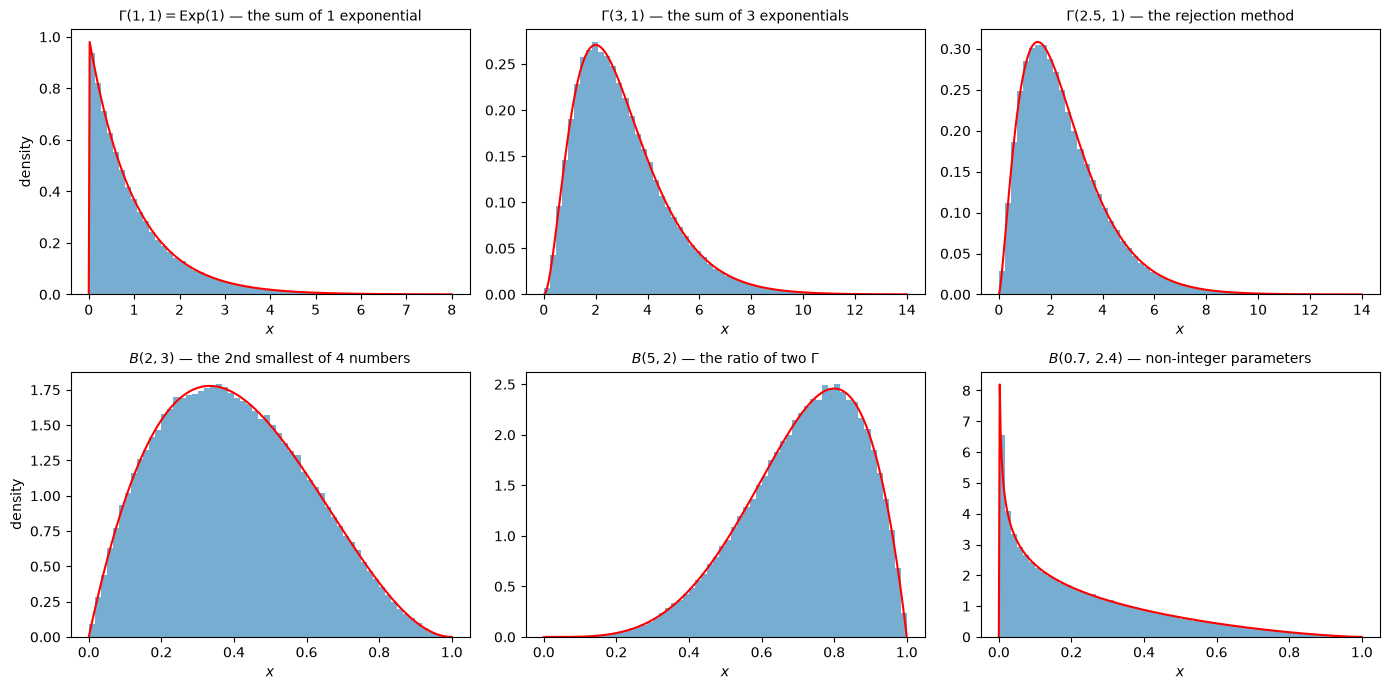

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

hist_density(axes[0][0], [gamma_integer(1) for _ in range(n)], (0, 8), gamma_pdf(1),
             r"$\Gamma(1,1) = \mathrm{Exp}(1)$ — the sum of 1 exponential")
hist_density(axes[0][1], [gamma_integer(3) for _ in range(n)], (0, 14), gamma_pdf(3),
             r"$\Gamma(3,1)$ — the sum of 3 exponentials")
hist_density(axes[0][2], [gamma_general(2.5) for _ in range(n)], (0, 14), gamma_pdf(2.5),
             r"$\Gamma(2.5,\,1)$ — the rejection method")

hist_density(axes[1][0], [beta_order(2, 3) for _ in range(n)], (0, 1), beta_pdf(2, 3),
             r"$B(2,3)$ — the 2nd smallest of 4 numbers")
hist_density(axes[1][1], [beta_ratio(5, 2) for _ in range(n)], (0, 1), beta_pdf(5, 2),
             r"$B(5,2)$ — the ratio of two $\Gamma$")
hist_density(axes[1][2], [beta_ratio(0.7, 2.4) for _ in range(n)], (0, 1), beta_pdf(0.7, 2.4),
             r"$B(0.7,\,2.4)$ — non-integer parameters")

for ax in axes.ravel():
    ax.set_xlabel("$x$")
axes[0][0].set_ylabel("density")
axes[1][0].set_ylabel("density")
plt.tight_layout()
plt.show()

All six histograms sit on their densities — including $B(0.7,\,2.4)$, which diverges at zero and is
nevertheless generated without any trouble.

## 3. The connection with $\chi^2$

The $\chi^2$ distribution with $k$ degrees of freedom, which we used in the tests of generators, is
$\Gamma(k/2,\,1/2)$. We verify that by two independent routes: as a sum of squares of normal variables
(the definition) and with our Γ generator.

  k           method        E X    exact        D X    exact
  1    by definition     1.0012        1     2.0232        2
  1 from Γ(k/2, 1/2)     0.9936        1     1.9693        2
  3    by definition     3.0032        3     6.0044        6


  3 from Γ(k/2, 1/2)     3.0064        3     6.0439        6


 10    by definition    10.0358       10    20.0337       20
 10 from Γ(k/2, 1/2)    10.0251       10    20.1109       20


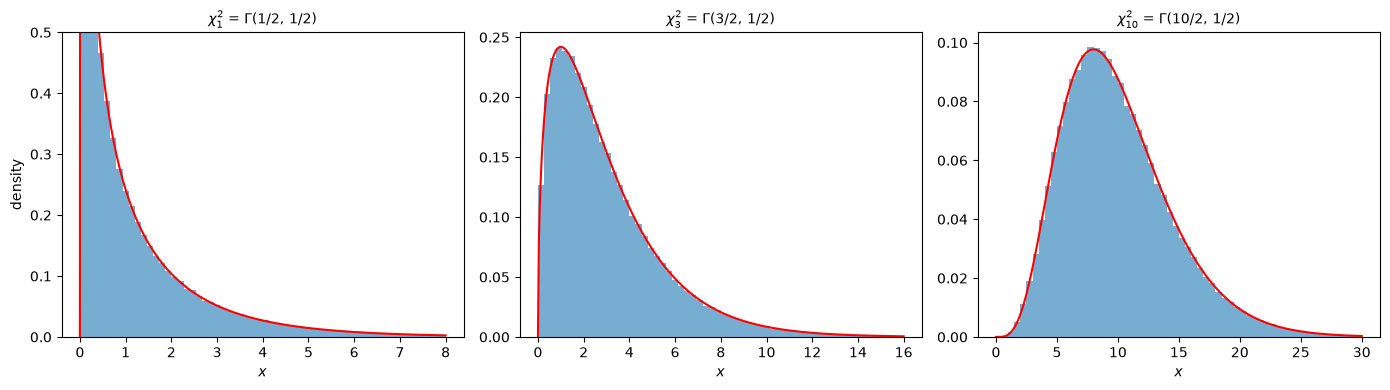

In [6]:
def chi2_from_definition(k):
    '''The sum of k squares of independent N(0,1) — the definition of χ².'''
    return sum(random.gauss(0, 1) ** 2 for _ in range(k))


def chi2_from_gamma(k):
    '''The same thing as Γ(k/2, 1/2) — one call instead of k.'''
    return gamma_general(k / 2.0, 0.5)


print(f"{'k':>3s} {'method':>16s} {'E X':>10s} {'exact':>8s} {'D X':>10s} {'exact':>8s}")
for k in (1, 3, 10):
    for name, gen in (("by definition", lambda: chi2_from_definition(k)), ("from Γ(k/2, 1/2)", lambda: chi2_from_gamma(k))):
        xs = [gen() for _ in range(100_000)]
        m, se = estimate(xs)
        v, _ = estimate([(x - k) ** 2 for x in xs])
        print(f"{k:>3d} {name:>16s} {m:>10.4f} {k:>8d} {v:>10.4f} {2 * k:>8d}")
        assert abs(m - k) < 5 * se

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (k, upper) in zip(axes, ((1, 8), (3, 16), (10, 30))):
    xs = [chi2_from_gamma(k) for _ in range(200_000)]
    hist_density(ax, xs, (0, upper), gamma_pdf(k / 2, 0.5),
                 f"$\\chi^2_{{{k}}}$ = $\\Gamma({k}/2,\\,1/2)$")
    ax.set_xlabel("$x$")
axes[0].set_ylabel("density")
axes[0].set_ylim(0, 0.5)   # the density of χ²_1 diverges at zero, otherwise the other panels would vanish
plt.tight_layout()
plt.show()

## Summary

| Distribution | When | Method | Cost |
|---|---|---|---|
| $\Gamma(k, \lambda)$, $k$ integer | Erlang, the wait for the $k$-th event | $-\ln(\gamma_1\cdots\gamma_k)/\lambda$ | $k$ numbers, **one** logarithm |
| $\Gamma(a, \lambda)$, any $a$ | the general case | Marsaglia–Tsang, rejection | ~1.03 tries per sample |
| $B(a, b)$, integer | an ordered sample | the $a$-th smallest of $a+b-1$ | $a+b-1$ numbers + sorting |
| $B(a, b)$, any | the general case | $X/(X+Y)$, $X\sim\Gamma(a)$, $Y\sim\Gamma(b)$ | two calls of Γ |
| $\chi^2_k$ | tests | $\Gamma(k/2,\,1/2)$ | one call instead of $k$ |

What to take away: for both distributions **$F$ cannot be inverted**, and yet they are easy to
generate — because we know their **structure**. Γ is a sum of exponentials, B is an ordered sample or a
ratio of gammas. Looking for the structure pays off before reaching for numerical inversion.

### Try it yourself

1. Verify that $\gamma_{(a)}$ out of $a+b-1$ numbers really does have $B(a,b)$, by comparing it with
   `beta_ratio` for $(a,b) = (3,4)$.
2. Compare the speed of `gamma_integer(10)` and `gamma_general(10)`. From which $k$ on does the
   rejection method pay off?
3. For $a < 1$ the Γ density has a singularity at zero. Verify that `gamma_general(0.3)` hits it —
   compare the histogram on log-log axes.
4. Generate $\chi^2_k$ for $k = 100$ both ways and measure the time. How does the cost of the
   definition grow, and how does the cost via Γ?
5. The Dirichlet distribution is a generalization of B: $(X_1,\dots,X_m)/\sum X_i$ with
   $X_i \sim \Gamma(a_i)$. Generate it for $m = 3$ and verify that the components have B distributions
   marginally.
6. Use `beta_ratio(2, 1)` and verify that it gives the same distribution as $\sqrt{\gamma}$ from
   exercise 2 (the density $2x$).